In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("wifi.csv")

print(df.head())

  Ping_latency  Download_speed  Upload_speed  Packet_loss_rate  \
0  21.85430535       42.395374     19.934759          0.999340   
1  47.78214379       43.456678     17.979781          1.493494   
2  37.93972738       86.182002     10.455388          1.125334   
3  31.93963179       37.300417     31.148800          0.166605   
4  12.02083882       87.616720     24.877960          0.371160   

   Router_distance  Network_congestion  ISP_quality  Connection_type_DSL  \
0         7.569985            1.369483     7.467012             0.000000   
1         2.660608            1.243015     6.215047             2.373401   
2         4.119757            3.416768          NaN             1.509861   
3         6.969526            4.864465     4.532849             0.000000   
4         5.338804            3.010885     7.114995             1.241954   

   Connection_type_Cable  Connection_type_Fiber  Signal_strength  \
0                    0.0               0.000000        76.190258   
1         

In [6]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Shape: (5000, 13)

Columns:
['Ping_latency', 'Download_speed', 'Upload_speed', 'Packet_loss_rate', 'Router_distance', 'Network_congestion', 'ISP_quality', 'Connection_type_DSL', 'Connection_type_Cable', 'Connection_type_Fiber', 'Signal_strength', 'Weather_conditions', 'Internet_speed']

Data Types:
Ping_latency                 str
Download_speed           float64
Upload_speed             float64
Packet_loss_rate         float64
Router_distance          float64
Network_congestion       float64
ISP_quality              float64
Connection_type_DSL      float64
Connection_type_Cable    float64
Connection_type_Fiber    float64
Signal_strength          float64
Weather_conditions       float64
Internet_speed           float64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Ping_latency           4852 no

In [7]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
Ping_latency             148
Download_speed           163
Upload_speed             176
Packet_loss_rate         157
Router_distance          165
Network_congestion       176
ISP_quality              172
Connection_type_DSL      195
Connection_type_Cable    164
Connection_type_Fiber    182
Signal_strength          181
Weather_conditions       162
Internet_speed           165
dtype: int64

Total Missing Values:
2206


In [8]:
# Convert Ping_latency into numeric format
df["Ping_latency"] = pd.to_numeric(
    df["Ping_latency"], errors="coerce"
)

# Convert all columns into numeric format
df = df.apply(pd.to_numeric, errors="coerce")

# Remove rows where target value is missing
df = df.dropna(subset=["Internet_speed"])

# Fill missing feature values using median
X_temp = df.drop(columns=["Internet_speed"])
df[X_temp.columns] = X_temp.fillna(X_temp.median())

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("\nCleaned dataset:")
print(df.head())

Missing values after cleaning:
0

Cleaned dataset:
   Ping_latency  Download_speed  Upload_speed  Packet_loss_rate  \
0     21.854305       42.395374     19.934759          0.999340   
1     47.782144       43.456678     17.979781          1.493494   
2     37.939727       86.182002     10.455388          1.125334   
3     31.939632       37.300417     31.148800          0.166605   
4     12.020839       87.616720     24.877960          0.371160   

   Router_distance  Network_congestion  ISP_quality  Connection_type_DSL  \
0         7.569985            1.369483     7.467012             0.000000   
1         2.660608            1.243015     6.215047             2.373401   
2         4.119757            3.416768     6.478544             1.509861   
3         6.969526            4.864465     4.532849             0.000000   
4         5.338804            3.010885     7.114995             1.241954   

   Connection_type_Cable  Connection_type_Fiber  Signal_strength  \
0                    

In [9]:
X = df.drop("Internet_speed", axis=1)
y = df["Internet_speed"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

X Shape: (4835, 12)
y Shape: (4835,)

Input Features:
['Ping_latency', 'Download_speed', 'Upload_speed', 'Packet_loss_rate', 'Router_distance', 'Network_congestion', 'ISP_quality', 'Connection_type_DSL', 'Connection_type_Cable', 'Connection_type_Fiber', 'Signal_strength', 'Weather_conditions']

Target:
Internet_speed


In [10]:
correlation = df.corr(numeric_only=True)

print(
    correlation["Internet_speed"]
    .sort_values(ascending=False)
)

Internet_speed           1.000000
Download_speed           0.959062
Connection_type_DSL      0.015038
Signal_strength          0.010591
Router_distance          0.009158
Weather_conditions       0.007807
Connection_type_Cable    0.006862
Packet_loss_rate         0.000874
Upload_speed             0.000580
Network_congestion      -0.000256
Ping_latency            -0.003127
Connection_type_Fiber   -0.003386
ISP_quality             -0.016976
Name: Internet_speed, dtype: float64


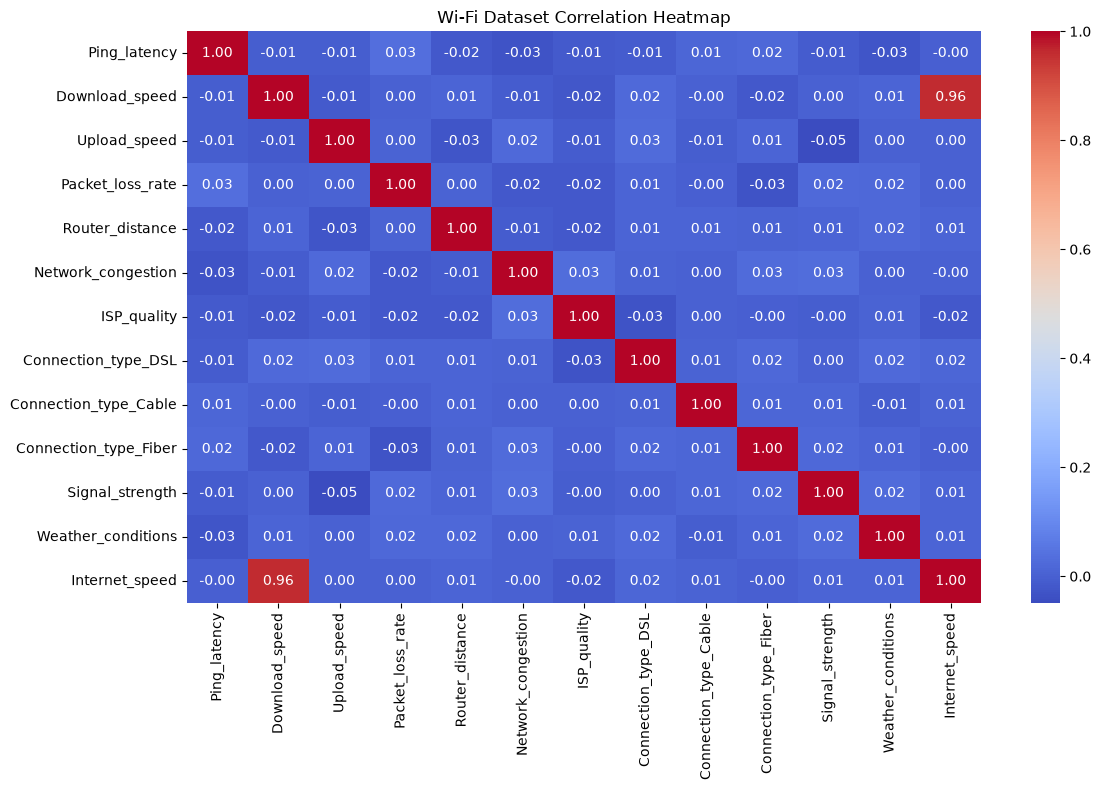

In [11]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Wi-Fi Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (3868, 12)
Testing Features: (967, 12)
Training Target: (3868,)
Testing Target: (967,)


In [13]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [14]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    "Actual Internet Speed": y_test.values,
    "Predicted Internet Speed": y_pred
})

print(result.head(10))

   Actual Internet Speed  Predicted Internet Speed
0             264.224866                177.756249
1            2794.952313               2569.611161
2             590.609652                736.723741
3            1074.741882               1281.165162
4             209.570610                 18.659376
5            3305.373769               2850.880252
6             281.128771                193.696687
7             594.734165                743.940112
8            3139.253340               2760.984566
9             173.686378               -112.935457


In [15]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Score Percentage:", round(r2 * 100, 2), "%")

MAE: 188.4
MSE: 58186.43
RMSE: 241.22
R2 Score: 0.9307
R2 Score Percentage: 93.07 %


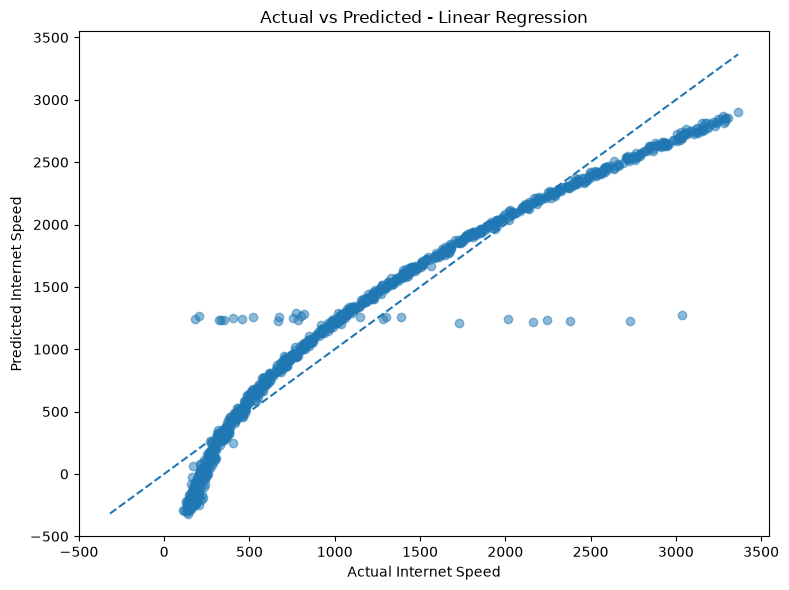

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Internet Speed")
plt.ylabel("Predicted Internet Speed")
plt.title("Actual vs Predicted - Linear Regression")

plt.tight_layout()
plt.show()

In [17]:
X_simple = df[["Download_speed"]]
y_simple = df["Internet_speed"]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

simple_model = LinearRegression()

simple_model.fit(X_train_s, y_train_s)

y_pred_s = simple_model.predict(X_test_s)

print("Simple Linear Regression Completed")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test_s, y_pred_s))

Simple Linear Regression Completed
Intercept: -469.14049482031396
Coefficient: 33.416918978562606
R2 Score: 0.9301353249508016


In [18]:
print("Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print(coefficients)

Intercept: -631.9469774297243
                  Feature  Coefficient
0            Ping_latency     0.383295
1          Download_speed    33.439833
2            Upload_speed     1.029531
3        Packet_loss_rate    -1.091228
4         Router_distance     0.892213
5      Network_congestion     8.783076
6             ISP_quality     1.307146
7     Connection_type_DSL    -3.187226
8   Connection_type_Cable     3.156777
9   Connection_type_Fiber     6.197745
10        Signal_strength     0.905139
11     Weather_conditions     0.394171


In [19]:
new_data = pd.DataFrame(
    [X.median().to_dict()],
    columns=X.columns
)

prediction = model.predict(new_data)

print(
    "Predicted Internet Speed:",
    round(prediction[0], 2)
)

Predicted Internet Speed: 1236.14


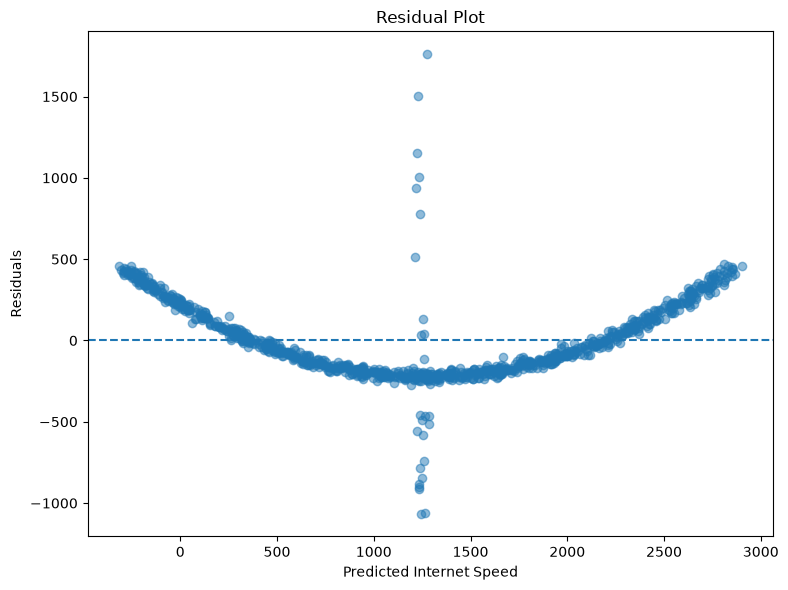

In [20]:
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Internet Speed")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.tight_layout()
plt.show()

In [21]:
print("========== LINEAR REGRESSION SUMMARY ==========")
print("Dataset Rows:", len(df))
print("Number of Features:", X.shape[1])
print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("================================================")

========== LINEAR REGRESSION SUMMARY ==========
Dataset Rows: 4835
Number of Features: 12
Training Rows: 3868
Testing Rows: 967
MAE: 188.4
RMSE: 241.22
R2 Score: 0.9307
